# Tiny transformer on Manhattan venue names

A walkthrough of `coursework/tiny_transformer/`. Each step points to a section of `NOTES.md` ([N1]…[N12]). The `.py` files are the source of truth; this notebook only calls them. Run `python -I coursework/tiny_transformer/train.py --ablation` first.

In [1]:
# Find the repo root (the folder that contains coursework/) and make it importable.
import os, sys
from pathlib import Path
root = Path.cwd()
while not (root / "coursework").is_dir():
    root = root.parent
sys.path.insert(0, str(root)); os.chdir(root)
print("repo root:", root)

repo root: /home/user/manhattan-bars-ml


## [N1]–[N2] Load, clean and split the names (real public SLA licence data, read-only)

In [2]:
from coursework.tiny_transformer.data import load_names, clean_all, split_names, Tokenizer, make_examples
raw = load_names()
names = clean_all(raw)
train, val = split_names(names, val_frac=0.1, seed=0)
print(len(raw), 'raw ->', len(names), 'clean;', len(train), 'train /', len(val), 'val')
print(names[:8])

5428 raw -> 4986 clean; 4487 train / 499 val
['1 HOTEL CENTRAL PARK', '10 GC HOSPITALITY AND BAR 10GC', '100 FEAST AND LOUNGE', '100 FORSYTH RESTAURANT', '100 MARKET PLACE', '102 W 86 NY', '1020 BAR', '1043 2ND AVE']


## [N3] Baselines in nats per character

In [3]:
import math
from coursework.tiny_transformer import baselines
tok = Tokenizer(train + val)
print('uniform', round(math.log(tok.vocab_size), 4))
print('unigram', round(baselines.unigram_loss(train, val, tok), 4))
print('bigram ', round(baselines.bigram_loss(train, val, tok), 4))

uniform 3.7612
unigram 3.0834
bigram  2.6426


## [N4] Tokens: x is the sequence, y is the same sequence shifted by one (-100 = ignored)

In [4]:
x, y = make_examples(['BAR 54'], tok, block_size=12)
print('x:', [tok.itos[i] for i in x[0]])
print('y:', [tok.itos[i] if i >= 0 else -100 for i in y[0]])

x: ['<s>', 'B', 'A', 'R', ' ', '5', '4', '<e>', '<e>', '<e>', '<e>', '<e>']
y: ['B', 'A', 'R', ' ', '5', '4', '<e>', -100, -100, -100, -100, -100]


## [N6]–[N7] Attention by hand (3 tokens, d = 2) and the same numbers from `model.Head`

In [5]:
import numpy as np, torch
from coursework.tiny_transformer.attention_by_hand import attention_by_hand, X, W_Q, W_K, W_V
from coursework.tiny_transformer.model import Head
np.set_printoptions(precision=4, suppress=True)
hand = attention_by_hand()
print('weights (rows sum to 1, future = 0):\n', hand['weights'])
print('output:\n', hand['out'])
head = Head(2, 2, 3, dropout=0.0)
with torch.no_grad():
    head.query.weight.copy_(torch.tensor(W_Q.T)); head.key.weight.copy_(torch.tensor(W_K.T)); head.value.weight.copy_(torch.tensor(W_V.T))
    print('torch Head output:\n', head(torch.tensor(X).float().unsqueeze(0))[0].numpy())

weights (rows sum to 1, future = 0):
 [[1.     0.     0.    ]
 [0.1956 0.8044 0.    ]
 [0.14   0.284  0.576 ]]
output:
 [[0.     1.    ]
 [0.8044 0.1956]
 [0.86   0.716 ]]
torch Head output:
 [[0.     1.    ]
 [0.8044 0.1956]
 [0.86   0.716 ]]


## [N8]–[N9] The model and its size

In [6]:
from coursework.tiny_transformer.model import TinyGPT, count_params
model = TinyGPT(tok.vocab_size)
print(f'{count_params(model):,} parameters')
print(model.blocks[0])

107,307 parameters
Block(
  (ln1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
  (attn): MultiHeadAttention(
    (heads): ModuleList(
      (0-3): 4 x Head(
        (key): Linear(in_features=64, out_features=16, bias=False)
        (query): Linear(in_features=64, out_features=16, bias=False)
        (value): Linear(in_features=64, out_features=16, bias=False)
        (dropout): Dropout(p=0.1, inplace=False)
      )
    )
    (proj): Linear(in_features=64, out_features=64, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (ln2): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
  (ffwd): FeedForward(
    (net): Sequential(
      (0): Linear(in_features=64, out_features=256, bias=True)
      (1): GELU(approximate='none')
      (2): Linear(in_features=256, out_features=64, bias=True)
      (3): Dropout(p=0.1, inplace=False)
    )
  )
)


## [N10] A short training demo (300 steps) — the full run is `train.py`

In [7]:
from coursework.tiny_transformer.train import train_model
cfg = dict(seed=0, n_layer=2, n_head=4, n_embd=64, block_size=32, dropout=0.1, batch_size=64,
           max_steps=300, eval_every=100, patience=5, lr_max=3e-3, lr_min=3e-4)
demo = train_model(cfg, {'train': train, 'val': val, 'tok': tok})

step   100  train 2.5026  val 2.5367


step   200  train 2.3581  val 2.4276


step   300  train 2.3022  val 2.3797


## [N12] Results of the full run (`outputs/metrics.json`, `outputs/loss_curve.png`)

{'params': 107307, 'steps_run': 1700, 'runtime_seconds': 41.3, 'best_val_loss': 2.1130712032318115, 'val_perplexity_per_char': 8.273612249669497, 'improvement_vs_bigram_pct': 20.03901185694184}
ablation: [('n_layer=1', 2.1435), ('block_size=16', 2.2119), ('dropout=0', 2.2049)]


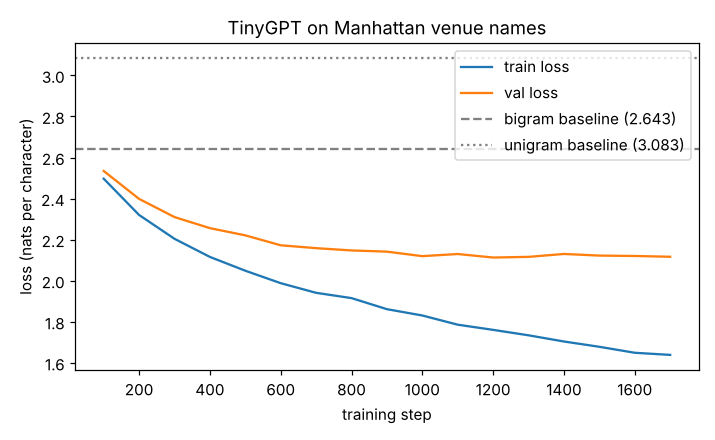

In [8]:
import json
from IPython.display import Image, display
m = json.loads(Path('coursework/tiny_transformer/outputs/metrics.json').read_text())
print({k: m[k] for k in ['params', 'steps_run', 'runtime_seconds', 'best_val_loss', 'val_perplexity_per_char', 'improvement_vs_bigram_pct']})
print('ablation:', [(a['variant'], round(a['best_val_loss'], 4)) for a in m.get('ablation', [])])
display(Image('coursework/tiny_transformer/outputs/loss_curve.png'))

## [N11] Sampling at three temperatures (SYNTHETIC names — never real venues)

In [9]:
from coursework.tiny_transformer.sample import load_model, sample_names, novelty_rate
gpt, itos = load_model()
train_set = set(train)
for t in (0.3, 0.8, 1.2):
    s = sample_names(gpt, itos, 50, t, seed=2)
    print(f'T={t}: novelty {novelty_rate(s, train_set):.0%}  e.g.', s[:4])

T=0.3: novelty 100%  e.g. ['THE TOWN THE STREET', 'LA BAR & GRILL', 'THE FLINGS', 'CAFE THE RESTAURANT']


T=0.8: novelty 98%  e.g. ['NYE TON WEST', 'SOSHI THE HELS', 'MADY UNDINER', 'IZAKAYA BELLIC']


T=1.2: novelty 100%  e.g. ['NYE BOBS DONKS STEATRE', 'HELBAMG ARUNT', 'ZLA IANO', 'CHEZE 39']
